# HCAI Fundamentals of Human-Centered AI Models — Homework 1
### World Development Indicators (WDI), 2022

**Instructor** Professor: Alejandro Abarca
**Student:** Gemar Johnston  
**Notebook:** `Johnston_Gemar__HW_1_v2.ipynb`

This notebook completes the requested WDI exploratory data analysis, grouping, boxplots, regression scatterplot, and 5-component Principal Component Analysis (PCA).

**Student software engineering choices used in this notebook**
- The CSV is expected to be named **`Merged_data.csv`** and to be in the same folder as this notebook.
- **GNI per capita** is used to create `Income_Level` and is dropped from the analysis table in Task 1, as the assignment requires. It is still plotted in the Task 2 boxplots, taken from the table before the drop, because the assignment asks for a boxplot of every listed variable. It is excluded from the PCA.
- The PCA therefore uses the remaining **seven continuous WDI variables**: inflation, trade, unemployment, greenhouse-gas emissions per capita, urban population, control of corruption, and rule of law.
- All PCA variables are standardized before PCA.
- Missing values are handled explicitly rather than silently filling them with arbitrary numbers. Boxplots use all available observations for each variable, while PCA uses complete cases across the seven PCA variables.
- The notebook validates required columns and creates reusable plotting functions so the analysis is reproducible rather than hard-coded to a particular number of countries.

## Software set up Section

**Run the first code cell before any other code.** It checks the active Jupyter Python kernel and automatically installs missing packages into that same environment. This specifically addresses `import numpy as np` / `No module named numpy` errors.
The notebook uses Matplotlib for all figures, so Seaborn is not required.
NOTE!: When opening it in Jupyter, run the first code cell before any other code cells. That cell is specifically designed to prevent the import numpy as np error. I ran into this issue when testing my notebook.


In [1]:
# ============================================================================
#    SETUP AND ENVIRONMENT CHECK
# ============================================================================
# Run this cell first. It verifies that the active Jupyter Python kernel has the packages required by this homework. If a package is missing or its import is broken, it is installed into the SAME Python environment used by
# the notebook. This fixes common errors such as: "No module named numpy".

from pathlib import Path
import sys
import subprocess
import importlib
import warnings

REQUIRED_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "IPython": "ipython",
}
#The code below checks for missing packages and makes sure the user has a smooth build of the notebook.  
missing_packages = []
for import_name, pip_name in REQUIRED_PACKAGES.items():
    try:
        importlib.import_module(import_name)
    except Exception:
        missing_packages.append(pip_name)

if missing_packages:
    print("Missing or broken packages:", ", ".join(sorted(set(missing_packages))))
    print("Installing into the active Jupyter Python environment...")
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--upgrade",
        *sorted(set(missing_packages))
    ])
    importlib.invalidate_caches() 


# This line of code will Import libraries only after the environment check/repair catch.
# Without accounting for the check/repair, the user will encounter an error. 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from IPython.display import display

warnings.filterwarnings("ignore", category=UserWarning)

# This code is used to save generated figures in a file located next to the notebook.
OUTPUT_DIR = Path("plots")
OUTPUT_DIR.mkdir(exist_ok=True)
SAVE_FIGURES = True

# Readable plotting defaults. No Seaborn dependency is required.

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 9,
})

print("Setup complete.")
print(f"Python interpreter: {sys.executable}")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")


Setup complete.
Python interpreter: c:\Users\gjohnston\AppData\Local\Programs\Python\Python310\python.exe
NumPy version: 2.2.6
Pandas version: 2.3.3


## 1. Import and validate `Merged_data.csv`

This cell reads the 2022 WDI CSV and checks for the exact indicator codes supplied in the assignment. The cell also locates the country-name field using common WDI column names.

In [2]:
# ============================================================================
# 1. IMPORT AND VALIDATE Merged_data.csv
# ============================================================================

# Accept either filename spelling.
candidates = [Path("Merged_data.csv"), Path("merged_data.csv")]
DATA_FILE = next((p for p in candidates if p.exists()), None)

if DATA_FILE is None:
    raise FileNotFoundError(
        "Could not find Merged_data.csv or merged_data.csv. "
        "Please place the .csv in the same folder as this notebook and run the cell again."
    )

df = pd.read_csv(DATA_FILE)
df.columns = df.columns.str.strip()

# Map the exact WDI indicator codes from the assignment to internal names.
# The uploaded CSV uses descriptive names, so aliases for both formats are supported.
WDI_CODE_TO_INTERNAL = {
    "NY.GNP.PCAP.KD": "GNI_per_capita",
    "FP.CPI.TOTL.ZG": "Inflation",
    "NE.TRD.GNFS.ZS": "Trade_as_percent_GDP",
    "SL.UEM.TOTL.ZS": "Unemployment_rate",
    "EN.GHG.ALL.PC.CE.AR5": "GHG_Emissions_per_Capita",
    "SP.URB.TOTL.IN.ZS": "Urban_pop_percent",
    "CC.EST": "Control_of_Corruption",
    "RL.EST": "Rule_of_Law",
}
#I had to refactor this cell to take an array of Aliases creating usable data.
ALIASES = {
    "GNI_per_capita": ["GNI_per_capita", "GNI per capita"],
    "Inflation": ["Inflation"],
    "Trade_as_percent_GDP": ["Trade_as_percent_GDP", "Trade as % of GDP"],
    "Unemployment_rate": ["Unemployment_rate", "Unemployment rate"],
    "GHG_Emissions_per_Capita": ["GHG_Emissions_per_Capita", "Greenhouse gas emissions per capita"],
    "Urban_pop_percent": ["Urban_pop_%", "Urban_pop_percent", "Urban population %"],
    "Control_of_Corruption": ["Control_of_Corruption", "Control of Corruption"],
    "Rule_of_Law": ["Rule_of_Law", "Rule of Law"],
}

resolved = {}
for wdi_code, internal_name in WDI_CODE_TO_INTERNAL.items():
    options = [wdi_code] + ALIASES[internal_name]
    match = next((col for col in options if col in df.columns), None)
    if match is None:
        raise ValueError(
            f"Required indicator {wdi_code} was not found. Expected one of: {options}"
        )
    resolved[internal_name] = match

country_options = ["Country Name", "Country", "Country_Name", "country", "country_name"]
COUNTRY_COL = next((c for c in country_options if c in df.columns), None)
if COUNTRY_COL is None:
    raise ValueError(
        "No country-name column was found. Expected one of: " + ", ".join(country_options)
    )

rename_map = {actual: internal for internal, actual in resolved.items()}
rename_map[COUNTRY_COL] = "Country"
work = df.rename(columns=rename_map).copy()
work["Country"] = work["Country"].astype(str).str.strip()

# Convert all analysis variables to numeric.
ALL_WDI_INTERNAL = list(WDI_CODE_TO_INTERNAL.values())
for col in ALL_WDI_INTERNAL:
    work[col] = pd.to_numeric(work[col], errors="coerce")

# Validate that the dataset is for 2022 when a year/date column exists.
# Due to the fact that we are required to use a specific .csv file, we will set some validation to catch none year 2022 files that share the same name.
DATE_COL = next((c for c in ["date", "Date", "year", "Year"] if c in work.columns), None)
if DATE_COL is not None:
    year_values = pd.to_numeric(work[DATE_COL], errors="coerce").dropna().unique()
    print(f"Year values found: {sorted(year_values.tolist())}")
    if len(year_values) != 1 or year_values[0] != 2022:
        warnings.warn("The CSV does not contain only 2022 observations.")

print(f"Imported file: {DATA_FILE}")
print(f"Rows loaded: {len(work):,}")
print("Required WDI indicators validated successfully.")
print("\nMissing values in required indicators:")
display(work[ALL_WDI_INTERNAL].isna().sum().rename("Missing values").to_frame())


Year values found: [2022]
Imported file: Merged_data.csv
Rows loaded: 128
Required WDI indicators validated successfully.

Missing values in required indicators:


,Missing values
GNI_per_capita,0
Inflation,0
Trade_as_percent_GDP,0
Unemployment_rate,0
GHG_Emissions_per_Capita,0
Urban_pop_percent,0
Control_of_Corruption,0
Rule_of_Law,0


## Task 1 — Generate `Income_Level` and dummy variables

The assignment provides these exact GNI thresholds:

| Income level | GNI per capita rule |
|---|---:|
| Low-income | GNI ≤ $1,145 |
| Lower middle-income | $1,146 ≤ GNI ≤ $4,515 |
| Upper middle-income | $4,516 ≤ GNI ≤ $14,005 |
| High-income | GNI > $14,005 |

GNI per capita is a continuous measure, so the whole-dollar cutoffs are applied as intervals: a country is Low-income if GNI ≤ 1,145, Lower middle-income if 1,145 < GNI ≤ 4,515, Upper middle-income if 4,515 < GNI ≤ 14,005, and High-income if GNI > 14,005. This means a value such as $1,145.50 is classified rather than left between two cutoffs. Countries with missing GNI are left missing rather than assigned to an incorrect group.

In [3]:
# ============================================================================
# TASK 1: GENERATE NEW VARIABLES
# ============================================================================

INCOME_ORDER = [
    "Low-income",
    "Lower middle-income",
    "Upper middle-income",
    "High-income",
]

# Classify by GNI per capita using the assignment's cut-offs. Each range is
# (lower, upper], so no value can fall into a gap between "<= 1145" and
# ">= 1146" (or the equivalent gaps at 4515 and 14005).
gni = work["GNI_per_capita"]
conditions = [
    gni <= 1145,
    (gni > 1145) & (gni <= 4515),
    (gni > 4515) & (gni <= 14005),
    gni > 14005,
]
work["Income_Level"] = np.select(conditions, INCOME_ORDER, default=None)
work["Income_Level"] = pd.Categorical(
    work["Income_Level"], categories=INCOME_ORDER, ordered=True
)

# Create a single dummy variable for each income level, including the first group.
DUMMY_NAMES = {
    "Low-income": "Income_Low_income",
    "Lower middle-income": "Income_Lower_middle_income",
    "Upper middle-income": "Income_Upper_middle_income",
    "High-income": "Income_High_income",
}
for level, dummy_name in DUMMY_NAMES.items():
    work[dummy_name] = (work["Income_Level"] == level).astype(int)

# Drop the original GNI column as explicitly required by the assignment parameters.
analysis_df = work.drop(columns=["GNI_per_capita"]).copy()

print("Income-level counts:")
income_counts = analysis_df["Income_Level"].value_counts().reindex(INCOME_ORDER, fill_value=0)
display(income_counts.rename("Countries").to_frame())

print("Dummy-variable columns created:")
print(list(DUMMY_NAMES.values()))
print(f"\nOriginal GNI column dropped: {'GNI_per_capita' not in analysis_df.columns}")
print(f"Countries left unclassified (missing GNI): {analysis_df['Income_Level'].isna().sum()}")

Income-level counts:


,Countries
Income_Level,
Low-income,16
Lower middle-income,40
Upper middle-income,30
High-income,42


Dummy-variable columns created:
['Income_Low_income', 'Income_Lower_middle_income', 'Income_Upper_middle_income', 'Income_High_income']

Original GNI column dropped: True
Countries left unclassified (missing GNI): 0


## Task 2 — Boxplots by Income Level

The assignment asks for a boxplot of each variable in the data section, so all eight variables are plotted. GNI per capita is taken from the table before the Task 1 column drop. Its boxes are separated by construction, because `Income_Level` was defined from GNI, so that plot shows the cutoffs working rather than a finding. The seven remaining WDI indicators are plotted by the derived income group.

The code below also produces a compact summary-statistics table (count, mean, median, quartiles, and standard deviation) so the written observations can be tied to numerical evidence rather than visual impressions alone.

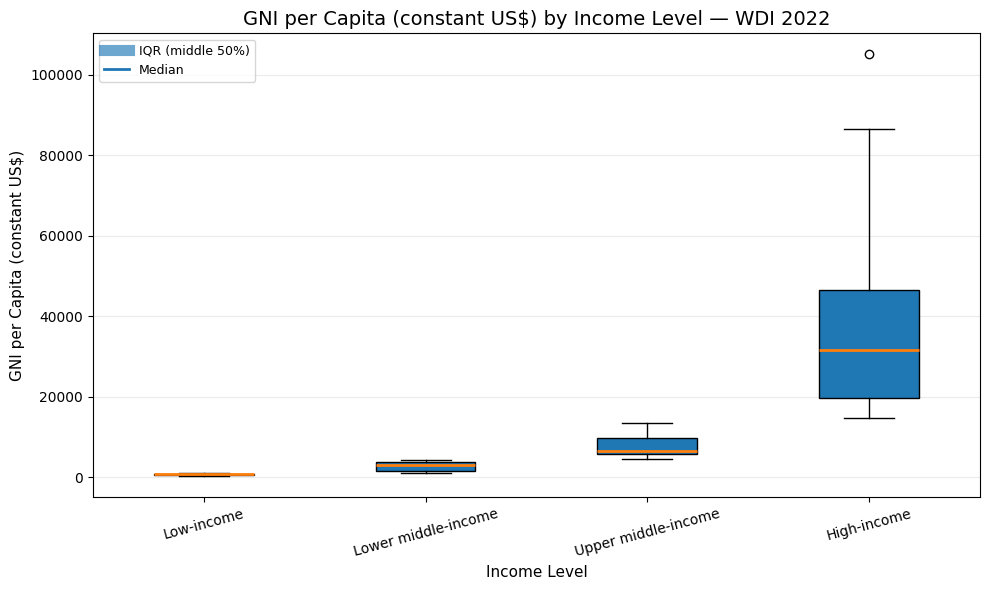

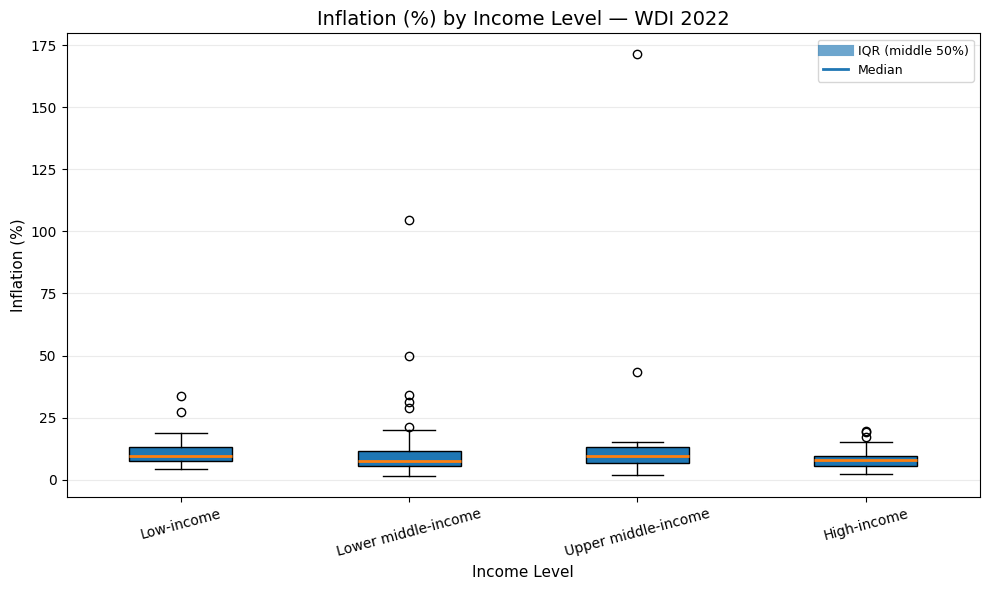

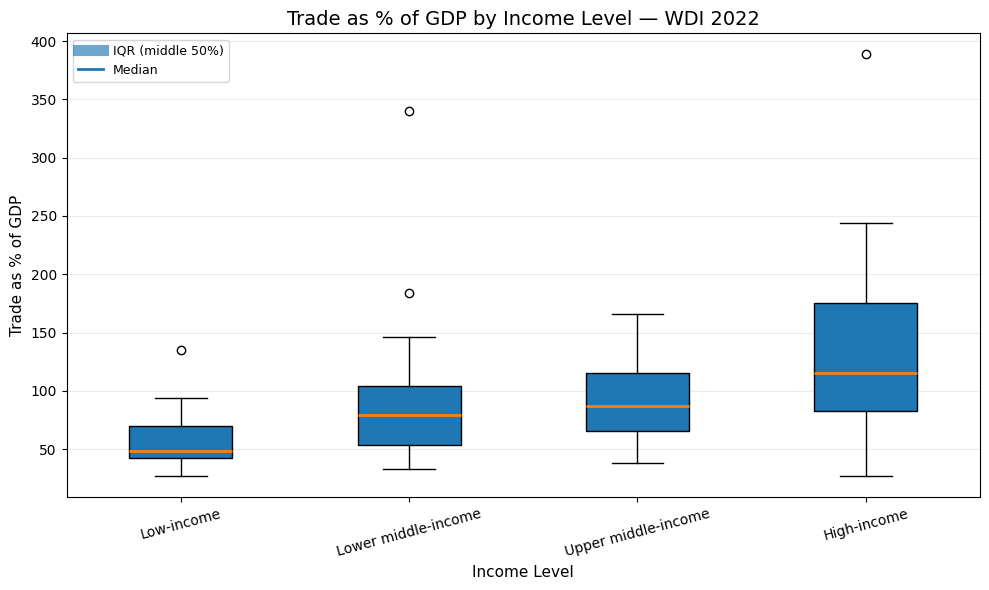

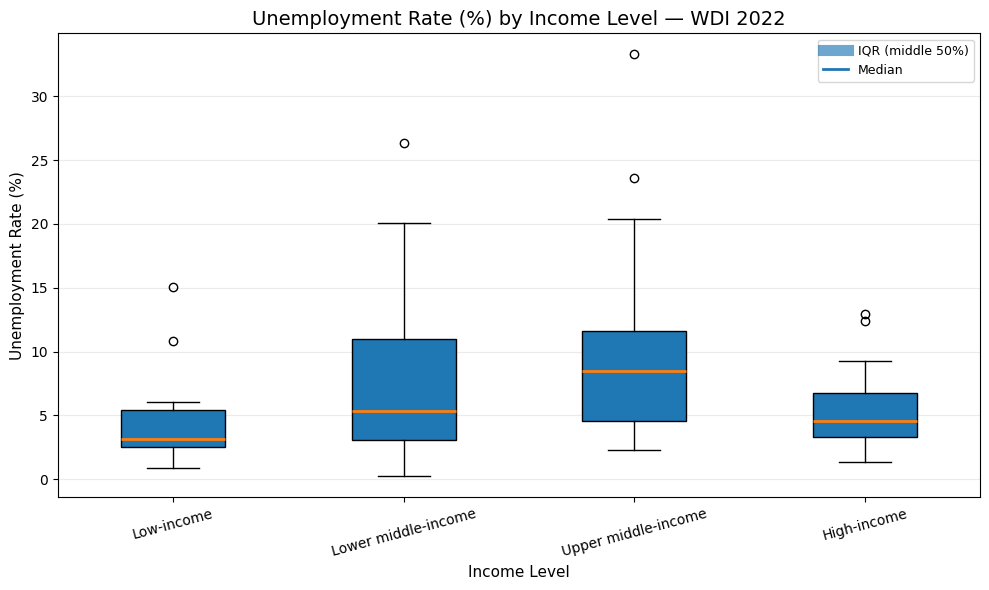

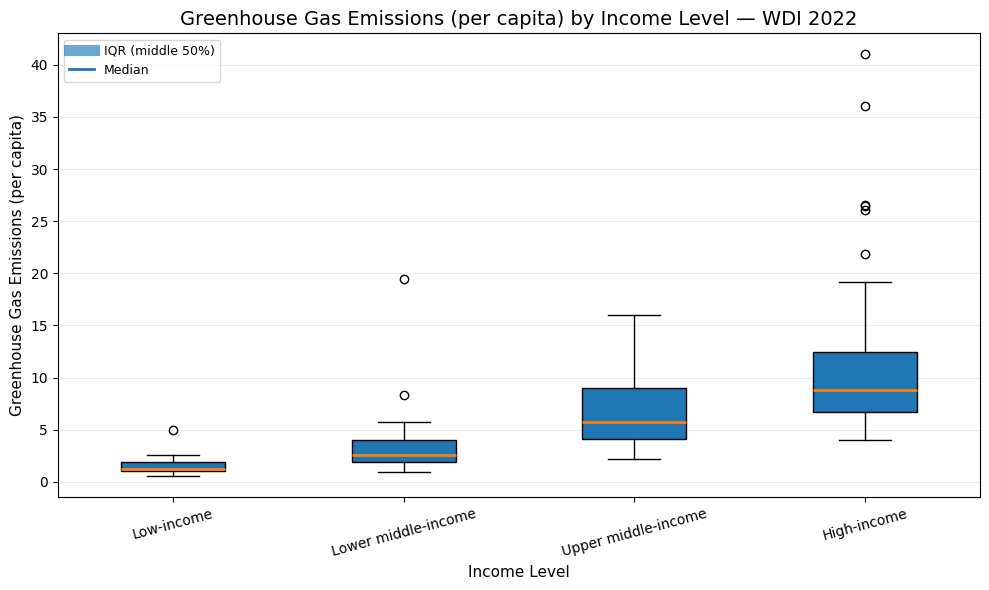

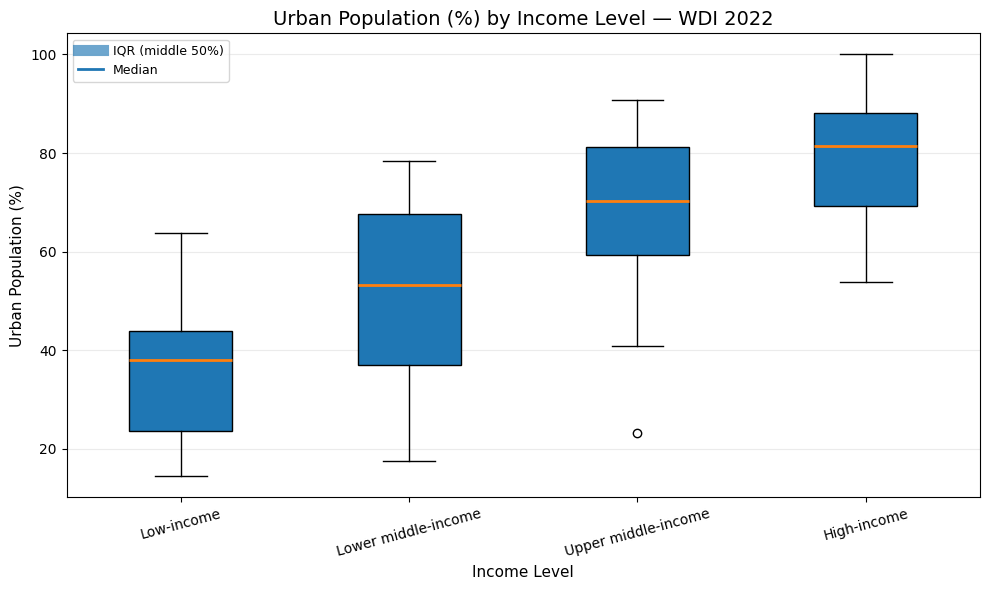

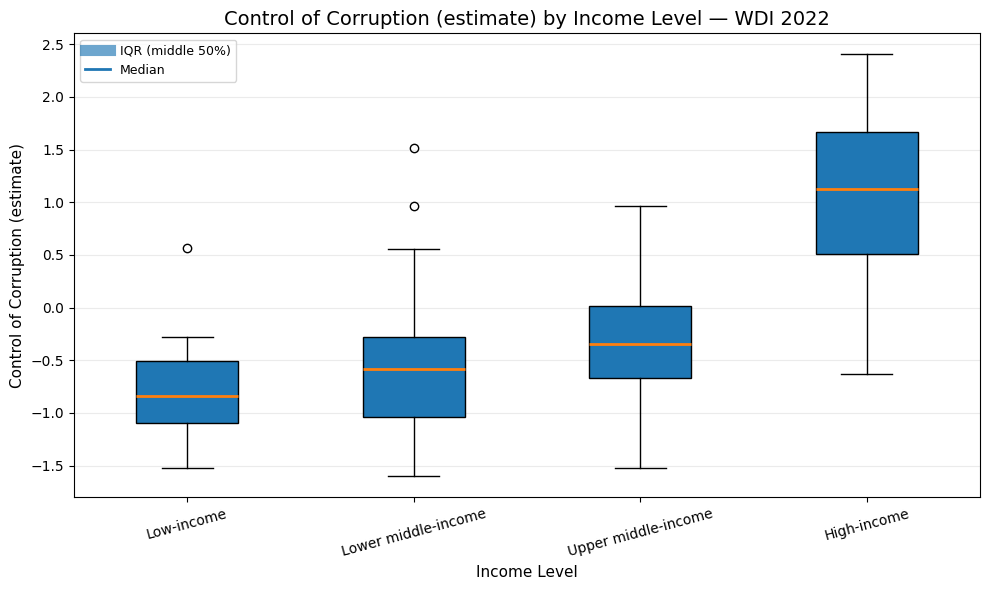

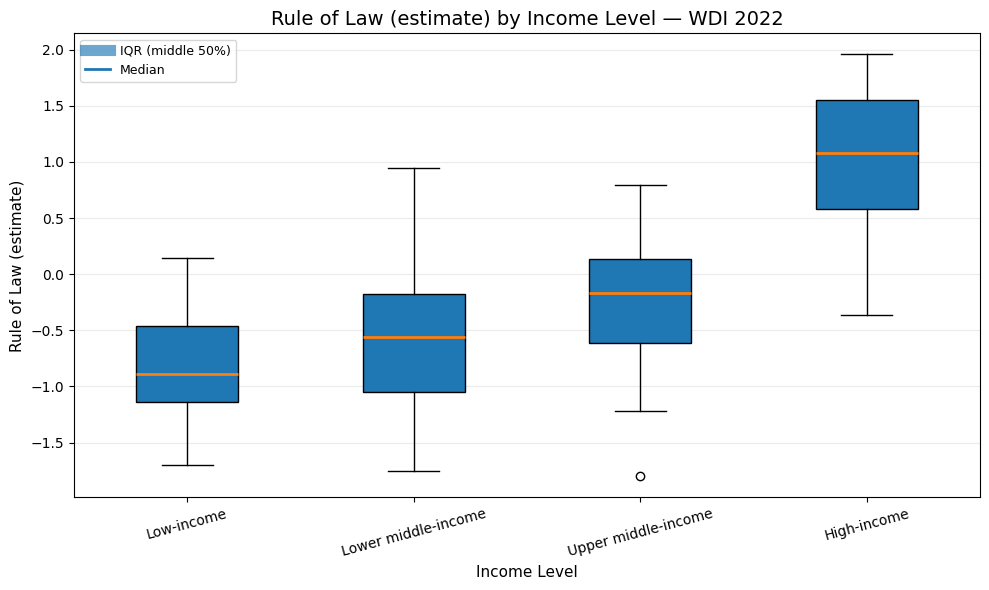

Summary statistics by income level:


Inflation                                         \
                        count    mean    50%     std    min      max   
Income_Level                                                           
Low-income                 16  12.224  9.508   8.236  4.350   33.890   
Lower middle-income        40  13.200  7.429  17.782  1.351  104.705   
Upper middle-income        30  15.678  9.523  30.287  1.974  171.205   
High-income                42   8.213  7.763   4.296  2.498   19.705   

                    Trade_as_percent_GDP                            ...  \
                                   count     mean      50%     std  ...   
Income_Level                                                        ...   
Low-income                            16   58.993   48.168  28.686  ...   
Lower middle-income                   40   89.296   79.035  53.627  ...   
Upper middle-income                   30   93.062   86.998  36.267  ...   
High-income                           42  129.763  115.350  68.328  ...   

                    Control_of_Corruption                      Rule_of_Law  \
                                      50%    std    min    max       count   
Income_Level                                                                 
Low-income                         -0.840  0.521 -1.518  0.561          16   
Lower middle-income                -0.587  0.646 -1.602  1.515          40   
Upper middle-income                -0.347  0.598 -1.526  0.968          30   
High-income                         1.130  0.762 -0.635  2.403          42   

                                                        
                      mean    50%    std    min    max  
Income_Level                                            
Low-income          -0.842 -0.891  0.482 -1.700  0.148  
Lower middle-income -0.541 -0.557  0.623 -1.750  0.948  
Upper middle-income -0.242 -0.168  0.623 -1.801  0.796  
High-income          1.056  1.080  0.573 -0.360  1.958  

[4 rows x 42 columns]

In [4]:
# ============================================================================
# TASK 2: BOXPLOTS BY INCOME LEVEL
# ============================================================================

LABELS = {
    "GNI_per_capita": "GNI per Capita (constant US$)",
    "Inflation": "Inflation (%)",
    "Trade_as_percent_GDP": "Trade as % of GDP",
    "Unemployment_rate": "Unemployment Rate (%)",
    "GHG_Emissions_per_Capita": "Greenhouse Gas Emissions (per capita)",
    "Urban_pop_percent": "Urban Population (%)",
    "Control_of_Corruption": "Control of Corruption (estimate)",
    "Rule_of_Law": "Rule of Law (estimate)",
}

WDI_VARS = [
    "Inflation",
    "Trade_as_percent_GDP",
    "Unemployment_rate",
    "GHG_Emissions_per_Capita",
    "Urban_pop_percent",
    "Control_of_Corruption",
    "Rule_of_Law",
]

# Every variable in the data section gets a boxplot. GNI was dropped from
# analysis_df in Task 1, so it is read from `work`, which still holds every
# column (including Income_Level).
BOXPLOT_VARS = ["GNI_per_capita"] + WDI_VARS

plot_df = work[["Country", "Income_Level"] + BOXPLOT_VARS].melt(
    id_vars=["Country", "Income_Level"],
    value_vars=BOXPLOT_VARS,
    var_name="Variable",
    value_name="Value",
)

for variable in BOXPLOT_VARS:
    subset = plot_df[plot_df["Variable"] == variable].dropna(subset=["Income_Level", "Value"])
    groups = [
        subset.loc[subset["Income_Level"] == level, "Value"].to_numpy()
        for level in INCOME_ORDER
    ]

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.boxplot(
        groups,
        showfliers=True,
        patch_artist=True,
        medianprops={"linewidth": 2},
    )
    # Set tick positions and labels explicitly so the income-level order is fixed
    # and the code works on every Matplotlib version.
    ax.set_xticks(range(1, len(INCOME_ORDER) + 1))
    ax.set_xticklabels(INCOME_ORDER, rotation=15)
    ax.set_title(f"{LABELS[variable]} by Income Level — WDI 2022")
    ax.set_xlabel("Income Level")
    ax.set_ylabel(LABELS[variable])
    ax.grid(axis="y", alpha=0.25)

    # Legend gives explanation of main boxplot elements.
    ax.legend(
        [plt.Line2D([0], [0], linewidth=8, alpha=0.65),
         plt.Line2D([0], [0], linewidth=2)],
        ["IQR (middle 50%)", "Median"],
        loc="best",
        frameon=True,
    )

    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(OUTPUT_DIR / f"boxplot_{variable}.png", dpi=300, bbox_inches="tight")
    plt.show()

# Numerical summary statistics support the written interpretation.
summary_stats = (
    analysis_df.groupby("Income_Level", observed=False)[WDI_VARS]
    .agg(["count", "mean", "median", "std", "min", "max"])
)
summary_stats = summary_stats.rename(columns={"median": "50%"}, level=1)

print("Summary statistics by income level:")
display(summary_stats.round(3))

In [5]:
# Create data-driven written observations from the summary statistics.
ECONOMIC_CONTEXT = {
    "Inflation": (
        "Inflation differences across income groups often reflect the strength of a "
        "country's monetary institutions and exchange-rate regime economies with "
        "weaker central-bank credibility or fiscal discipline are more prone to episodes "
        "of high or volatile inflation, and those episodes tend to widen the spread "
        "within a group as much as they shift its center."
    ),
    "Trade_as_percent_GDP": (
        "Trade openness is shaped by integration into global value chains and by trade "
        "infrastructure and logistics, but small or entrepot economies can post very high "
        "trade ratios regardless of income level, so this variable does not have to move "
        "in lock-step with income."
    ),
    "Unemployment_rate": (
        "Unemployment is shaped as much by labor-market structure (informality, labor-"
        "force participation, social-insurance design) as by income level, so it is "
        "typically one of the noisier, less monotonic variables across income groups."
    ),
    "GHG_Emissions_per_Capita": (
        "Greenhouse-gas emissions per capita are tied to energy consumption per person "
        "and historical reliance on fossil fuels, which usually rises with income, though "
        "efficiency gains and service-based economies can moderate this at the top of the "
        "income distribution."
    ),
    "Urban_pop_percent": (
        "Urbanization usually rises with income as economies shift from agriculture "
        "toward industry and services, which concentrate jobs in cities."
    ),
    "Control_of_Corruption": (
        "Control of Corruption is one of the most consistently income-correlated "
        "governance indicators, since higher-income countries generally have stronger "
        "rule-based institutions and more effective anti-corruption enforcement."
    ),
    "Rule_of_Law": (
        "Rule of Law is drawn from the same institutional-quality framework as Control of "
        "Corruption and reflects the strength of contract enforcement, property rights, "
        "and the judiciary dimensions that tend to strengthen as economies develop."
    ),
}

print("Key observations to use for boxplots:\n")

for variable in WDI_VARS:
    grouped = analysis_df.groupby("Income_Level", observed=False)[variable]
    medians = grouped.median().dropna()
    means = grouped.mean().dropna()
    stds = grouped.std().dropna()

    if len(medians) >= 2:
        lowest_level = medians.idxmin()
        highest_level = medians.idxmax()
        spread_level = stds.idxmax() if len(stds.dropna()) else "N/A"

        # Check whether the median moves in one consistent direction across the
        # four ordered income groups, or whether the relationship is non-monotonic.
        ordered_medians = grouped.median().reindex(INCOME_ORDER).dropna()
        if len(ordered_medians) >= 3 and ordered_medians.is_monotonic_increasing:
            trend_note = "rises steadily from Low-income to High-income"
        elif len(ordered_medians) >= 3 and ordered_medians.is_monotonic_decreasing:
            trend_note = "falls steadily from Low-income to High-income"
        else:
            trend_note = "does not move in a single consistent direction across the four income groups"

        print(
            f"• {LABELS[variable]}: the median {trend_note}. The lowest group median is "
            f"{lowest_level} ({medians[lowest_level]:.3f}), while the highest is "
            f"{highest_level} ({medians[highest_level]:.3f}). The largest within-group "
            f"standard deviation is in {spread_level}, indicating that group is the most "
            f"internally heterogeneous on this measure.\n  Why this matters: "
            f"{ECONOMIC_CONTEXT[variable]}\n"
        )

print("Interpretation guidance:")
print("• Compare medians to discuss typical differences between income groups.")
print("• Compare IQRs (the height of each box) to discuss within-group variability.")
print("• Compare whiskers and individual points to identify unusually high/low observations.")
print("• A visible group difference is descriptive; it does not by itself establish causation.")

Key observations to use for boxplots:

• Inflation (%): the median does not move in a single consistent direction across the four income groups. The lowest group median is Lower middle-income (7.429), while the highest is Upper middle-income (9.523). The largest within-group standard deviation is in Upper middle-income, indicating that group is the most internally heterogeneous on this measure.
  Why this matters: Inflation differences across income groups often reflect the strength of a country's monetary institutions and exchange-rate regime economies with weaker central-bank credibility or fiscal discipline are more prone to episodes of high or volatile inflation, and those episodes tend to widen the spread within a group as much as they shift its center.

• Trade as % of GDP: the median rises steadily from Low-income to High-income. The lowest group median is Low-income (48.168), while the highest is High-income (115.350). The largest within-group standard deviation is in High-inco

### Written observations: boxplots (Task 2)

The table gives the group medians from the summary statistics. All figures use the same income order, so medians and spreads can be compared directly.

| Variable | Low-income | Lower middle-income | Upper middle-income | High-income |
|---|---:|---:|---:|---:|
| Inflation (%) | 9.51 | 7.43 | 9.52 | 7.76 |
| Trade as % of GDP | 48.17 | 79.04 | 87.00 | 115.35 |
| Unemployment rate (%) | 3.18 | 5.31 | 8.51 | 4.54 |
| GHG emissions per capita | 1.24 | 2.58 | 5.76 | 8.77 |
| Urban population (%) | 37.93 | 53.31 | 70.28 | 81.47 |
| Control of Corruption | -0.84 | -0.59 | -0.35 | 1.13 |
| Rule of Law | -0.89 | -0.56 | -0.17 | 1.08 |

The GNI per capita boxplot separates the groups by construction, because `Income_Level` was defined from GNI. It confirms that the cutoffs were applied correctly and says nothing else.

Several variables rise steadily with income. Urban population rises at each step, from a median of about 38% in low-income countries to about 81% in high-income countries, and the interquartile ranges of the two ends do not overlap. Greenhouse gas emissions per capita follow the same pattern, with medians rising from 1.24 to 8.77 tonnes per person, and the high-income group has the widest spread (standard deviation 8.47), driven partly by Bahrain at 41.0. Trade as a share of GDP also rises, from a median of 48% to 115%, but its high-income spread is very wide (standard deviation 68.3) because a few small economies have very high trade ratios, such as Luxembourg at about 389%.

Governance shows the sharpest break. Control of Corruption and Rule of Law both increase across the three lower groups, but by modest amounts (roughly 0.25 to 0.4 units per step). The jump to the high-income group is much larger: the high-income median is about 1.1 on both indicators, while the upper-middle-income median falls between -0.35 and -0.17. The upper-middle-income interquartile range ends at 0.02 (Control of Corruption) and 0.14 (Rule of Law), below the high-income lower quartile of 0.51 and 0.58, so the two groups barely overlap.

Inflation and unemployment do not follow income. Inflation medians sit between 7.4% and 9.5% in all four groups, so the center is nearly flat. The spread is not flat: the standard deviation is 8.2 for low-income countries, 17.8 for lower-middle-income, 30.3 for upper-middle-income, and 4.3 for high-income. The lower-middle and upper-middle groups are dominated by extreme cases, including Lebanon (about 171%) in the upper-middle group and Zimbabwe (about 105%) in the lower-middle group. Unemployment peaks in the upper-middle-income group (median 8.5%), is lower in the high-income group (4.5%), and is lowest in the low-income group (3.2%). This is consistent with informal labor markets in poorer economies, where many people work without being counted as unemployed. South Africa, at 33.3%, is the highest value in the sample.

Taken together, urbanization and governance line up closely with income, while inflation and unemployment vary widely within every group. Income is therefore a good guide to some structural differences between countries and a poor guide to others. All of this is descriptive: a difference between groups shows an association, not a cause.

## Task 6 — Control of Corruption vs. Rule of Law

This scatterplot labels every country, adds a least-squares regression line, and reports the Pearson correlation and $R^2$. The relationship is interpreted as an association, not as evidence that one governance indicator causes the other.

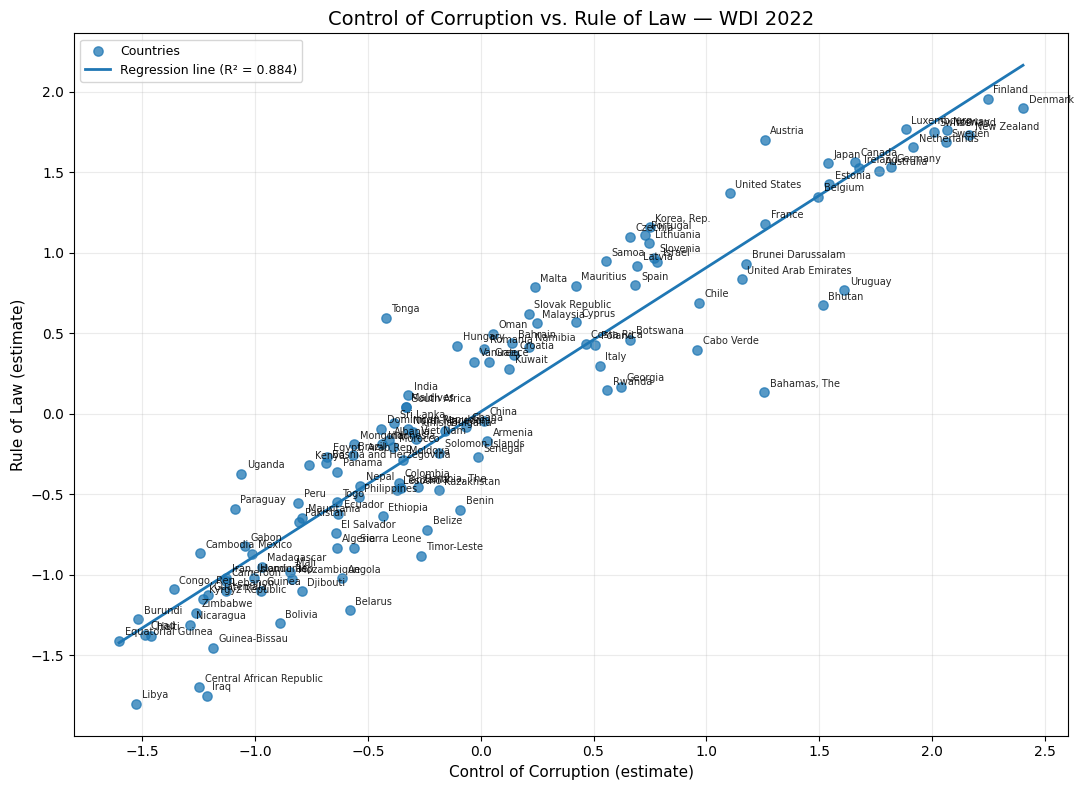

Pearson correlation (r): 0.940
R²: 0.884
Regression equation: Rule of Law = 0.896 × Control of Corruption + 0.013

This strong positive relationship makes conceptual sense: Control of Corruption and Rule of Law are both components of the World Bank's Worldwide Governance Indicators and measure closely related aspects of the same underlying construct the quality and predictability of a country's public institutions. Countries with independent, well-functioning courts and enforceable property rights (high Rule of Law) also tend to have the oversight mechanisms needed to detect and deter bribery and elite capture (high Control of Corruption), so the two indicators are expected to move together rather than independently. This association should still be read as descriptive, not causal both variables are likely downstream of a broader set of institutional and historical factors.


In [ ]:
# ============================================================================
# TASK 6: CONTROL OF CORRUPTION VS. RULE OF LAW
# ============================================================================

gov_df = analysis_df[["Country", "Control_of_Corruption", "Rule_of_Law"]].dropna().copy()
if len(gov_df) < 2:
    raise ValueError("At least two complete country observations are required for Task 6.")

x = gov_df["Control_of_Corruption"].to_numpy()
y = gov_df["Rule_of_Law"].to_numpy()
correlation = np.corrcoef(x, y)[0, 1]
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 200)
y_line = slope * x_line + intercept
r_squared = correlation ** 2

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(gov_df["Control_of_Corruption"], gov_df["Rule_of_Law"],
    alpha=0.75, s=45, label="Countries")
ax.plot(x_line, y_line, linewidth=2,
        label=f"Regression line (R² = {r_squared:.3f})")

for _, row in gov_df.iterrows():
    ax.annotate(
        row["Country"],
        (row["Control_of_Corruption"], row["Rule_of_Law"]),
        xytext=(4, 4), textcoords="offset points", fontsize=7, alpha=0.85
    )

ax.set_title("Control of Corruption vs. Rule of Law — WDI 2022")
ax.set_xlabel("Control of Corruption (estimate)")
ax.set_ylabel("Rule of Law (estimate)")
ax.grid(alpha=0.25)
ax.legend(loc="best", frameon=True)
fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "task6_control_of_corruption_vs_rule_of_law.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Pearson correlation (r): {correlation:.3f}")
print(f"R²: {r_squared:.3f}")
print(f"Regression equation: Rule of Law = {slope:.3f} × Control of Corruption + {intercept:.3f}")

# Data-driven relationship.
if correlation > 0.5:
    sense_note = (
        "This strong positive relationship makes conceptual sense: Control of Corruption "
        "and Rule of Law are both components of the World Bank's Worldwide Governance "
        "Indicators and measure closely related aspects of the same underlying construct "
        "the quality and predictability of a country's public institutions. Countries "
        "with independent, well-functioning courts and enforceable property rights (high "
        "Rule of Law) also tend to have the oversight mechanisms needed to detect and "
        "deter bribery and elite capture (high Control of Corruption), so the two "
        "indicators are expected to move together rather than independently. This "
        "association should still be read as descriptive, not causal both variables "
        "are likely downstream of a broader set of institutional and historical factors."
    )
elif correlation > 0:
    sense_note = (
        "The positive relationship is broadly consistent with expectations, since Control "
        "of Corruption and Rule of Law are both governance-quality indicators from the "
        "same World Bank framework and typically move together, though the relationship "
        "here is weaker than the very high correlation usually reported between these two "
        "indicators globally worth a second look at outlying countries pulling the fit "
        "down."
    )
else:
    sense_note = (
        "A non-positive relationship would be unusual here: Control of Corruption and Rule "
        "of Law are both governance-quality indicators from the same World Bank framework "
        "and are almost always strongly positively correlated across countries, so a flat "
        "or negative slope is worth double-checking against the raw data and outlier "
        "countries before concluding the relationship truly runs counter to expectations."
    )
print("\n" + sense_note)

### Written comment: Control of Corruption vs. Rule of Law (Task 6)

The two indicators are strongly related: the Pearson correlation is r = 0.940, so R² = 0.884. The fitted line, Rule of Law ≈ 0.896 × Control of Corruption + 0.013, has a slope close to 1. Because both indicators are standardized estimates on a similar scale, the slope close to 1 says that a country's position on one is almost the same as its position on the other.

This makes sense. Both come from the World Bank's Worldwide Governance Indicators, and both measure the quality of a country's public institutions. Countries with independent courts and enforceable property rights (high Rule of Law) also tend to have oversight mechanisms that make bribery and elite capture harder (high Control of Corruption), so the two are expected to move together.

The correlation should be read with some care. The two indicators draw on many of the same underlying data sources, which inflates their apparent agreement. A strong correlation shows they measure closely related things; it does not show that one causes the other, and it does not mean the two are interchangeable in every country.

# Tasks 7–8  Principal Component Analysis (PCA)

### PCA variables

Because the original GNI variable was dropped in Task 1 and the four income dummies represent the same GNI-derived grouping rather than independent continuous measures, the PCA uses these seven continuous indicators:

- Inflation
- Trade as % of GDP
- Unemployment rate
- Greenhouse gas emissions per capita
- Urban population %
- Control of Corruption
- Rule of Law

PCA is applied only to complete cases for these seven variables, and **all seven variables are standardized first** so differences in measurement scale do not dominate the decomposition.

In [7]:
# Select the seven continuous variables for PCA.
PCA_VARS = WDI_VARS.copy()

# Keep Income_Level alongside the seven PCA variables so later plots can
# color countries by income group. Completeness is still required only for
# the seven continuous PCA variables (dropna is scoped to PCA_VARS), so the
# PCA sample size is unaffected by this addition.
pca_df = analysis_df[["Country", "Income_Level"] + PCA_VARS].dropna(subset=PCA_VARS).copy()

if len(pca_df) < 5:
    raise ValueError("At least five complete observations are required to compute five PCA components.")
if len(PCA_VARS) < 5:
    raise ValueError("At least five PCA variables are required to compute five components.")

# Standardize every variable to mean 0 and standard deviation 1.
scaler = StandardScaler()
X_std = scaler.fit_transform(pca_df[PCA_VARS])

# Fit PCA with exactly five components, as required by the assignment.
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_std)

# Create readable component names.
PC_NAMES = [f"PC{i}" for i in range(1, 6)]

# Store observation scores in a labeled DataFrame, with Income_Level carried
# along so the PCA scatter plot and biplot can be color-coded by income group.
pca_scores = pd.DataFrame(X_pca, columns=PC_NAMES, index=pca_df["Country"])
pca_scores["Income_Level"] = pca_df["Income_Level"].to_numpy()

# Shared color palette for income-level groups, reused by the Task 8 plots.
INCOME_COLORS = {
    "Low-income": "#d62728",
    "Lower middle-income": "#ff7f0e",
    "Upper middle-income": "#1f77b4",
    "High-income": "#2ca02c",
}

# Calculate variance explained and cumulative variance explained.
explained_variance = pd.Series(
    pca.explained_variance_ratio_, index=PC_NAMES, name="Variance explained"
)
cumulative_variance = explained_variance.cumsum().rename("Cumulative variance")

variance_table = pd.concat([explained_variance, cumulative_variance], axis=1)
variance_table["Variance explained"] *= 100
variance_table["Cumulative variance"] *= 100

print(f"PCA observations used: {len(pca_df):,}")
print(f"PCA variables used: {len(PCA_VARS)}")
print("\nVariance explained by each component:")
display(variance_table.round(2))

PCA observations used: 128
PCA variables used: 7

Variance explained by each component:


,Variance explained,Cumulative variance
PC1,40.37,40.37
PC2,17.17,57.55
PC3,13.18,70.72
PC4,11.87,82.59
PC5,11.18,93.77


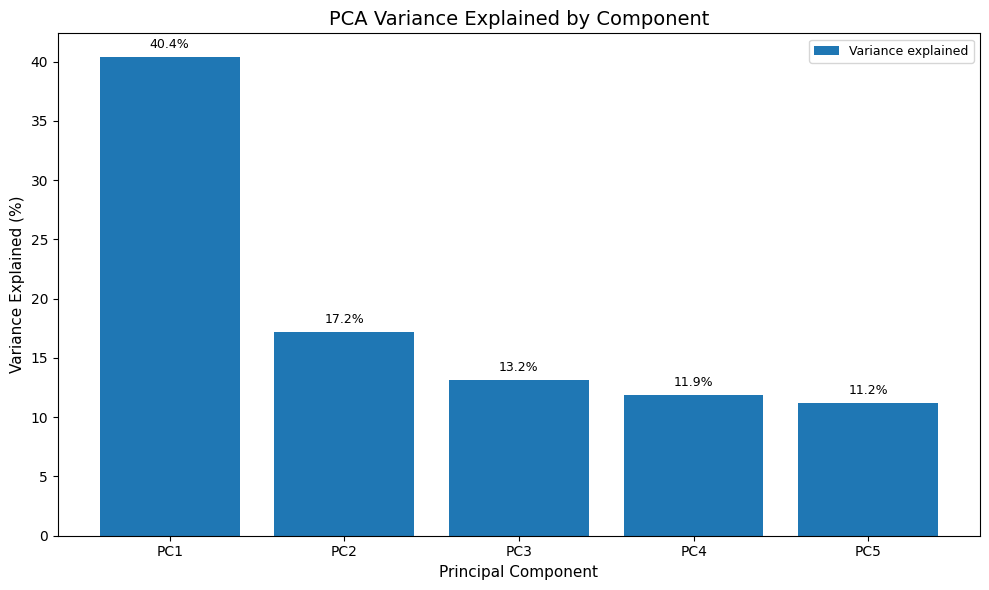

The first two components explain 57.5% of the standardized-data variance. The first five components explain 93.8%.
No single component dominates (PC1 explains 40.4%, PC2 explains 17.2%). That spread suggests the seven indicators capture more than one distinct dimension of country variation -- for example, an institutional-quality/development dimension and a separate macroeconomic or structural dimension -- rather than a single 'rich vs. poor' axis. A 2-D PCA map (PC1 vs. PC2) will therefore leave a meaningful share of the total variation unrepresented, which the squared-cosine plots below quantify directly.


In [8]:
# Task 7: Barplot of variance explained by each principal component.
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    PC_NAMES,
    explained_variance.values * 100,
    label="Variance explained",
)

ax.set_title("PCA Variance Explained by Component")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Variance Explained (%)")
ax.legend(loc="best", frameon=True)

# Add percentage labels above each bar for easy grading and interpretation.
for bar, value in zip(bars, explained_variance.values * 100):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "task7_variance_explained.png", dpi=300, bbox_inches="tight")
plt.show()

print(
    f"The first two components explain {explained_variance.iloc[:2].sum() * 100:.1f}% "
    f"of the standardized-data variance. The first five components explain "
    f"{explained_variance.sum() * 100:.1f}%."
)

# Data-driven read on the SHAPE of the variance decomposition: does one
# component dominate, or are the seven indicators spread across several
# distinct dimensions?
dominant_share = explained_variance.iloc[0]
second_share = explained_variance.iloc[1]
if dominant_share > 0.5:
    shape_note = (
        f"PC1 alone accounts for the majority of the standardized variance "
        f"({dominant_share * 100:.1f}%), which suggests a single dominant axis -- most "
        f"likely a general development/governance axis -- organizes most of the "
        f"variation across these seven indicators. PC2 and beyond mainly pick up "
        f"secondary, narrower contrasts."
    )
else:
    shape_note = (
        f"No single component dominates (PC1 explains {dominant_share * 100:.1f}%, PC2 "
        f"explains {second_share * 100:.1f}%). That spread suggests the seven indicators "
        f"capture more than one distinct dimension of country variation -- for example, "
        f"an institutional-quality/development dimension and a separate macroeconomic or "
        f"structural dimension -- rather than a single 'rich vs. poor' axis. A 2-D PCA "
        f"map (PC1 vs. PC2) will therefore leave a meaningful share of the total "
        f"variation unrepresented, which the squared-cosine plots below quantify "
        f"directly."
    )
print(shape_note)

### Variance explained (Task 7)

The barplot shows that PC1 explains 40.4% of the variance, PC2 explains 17.2%, PC3 explains 13.2%, PC4 explains 11.9%, and PC5 explains 11.2%. Together, the first two components explain 57.5%, and all five explain 93.8%.

The two common decision rules give different answers. The Kaiser criterion keeps components whose eigenvalue is greater than 1 (equivalently, whose share of variance is above 1/7, or about 14.3%, for seven standardized variables). That keeps only PC1 (eigenvalue 2.85) and PC2 (eigenvalue 1.21). The scree pattern also shows no sharp elbow after PC2: PC3 through PC5 each explain a similar share, between 11% and 13%. The assignment asks for five components, and five is a reasonable choice here because it captures 93.8% of the standardized variance and the two omitted components explain only 6.2%.

The significance of the model is in the first two components. A two-dimensional map captures 57.5% of the variation, so about 42.5% of it is not shown on the PC1-PC2 plots. The next section checks how well that map represents each country and each variable.

### Task 7 — Squared cosines for observations and variables

For observations, the squared cosine for component $k$ is the squared component score divided by the observation's **total squared distance from the centroid in the original standardized variable space** (all seven indicators). Because PCA is an orthogonal rotation, this total is mathematically identical to what you would get by summing squared scores across *all* possible components so it is computed directly from the standardized data (`X_std`) rather than only from the 5 retained components. Using just the 5 retained components as the denominator would slightly *overstate* every squared cosine, since it silently treats the reduced 5-component model as if it were the whole picture.

For variables, we use the correlations between standardized original variables and the PCA components. Each of these correlations is already bounded between -1 and 1 by construction, so no extra denominator is needed. The **first-two-component total squared cosine** is the sum of the PC1 and PC2 squared correlations and represents how well each variable is represented by the two-dimensional PCA map.

In [9]:
# ----- Squared cosines for observations (rows) -----
# The correct denominator is each observation's total squared distance from
# the centroid in the ORIGINAL standardized variable space (all 7 variables),
# not just the 5 retained PCA components. Because PCA is an orthogonal
# rotation, that total squared distance is mathematically identical to the
# sum of squared scores across ALL possible components so we can read it
# directly off X_std without needing to compute the 2 extra components.
obs_sq_distance = pd.Series((X_std ** 2).sum(axis=1), index=pca_scores.index)

obs_cos2 = pd.DataFrame(index=pca_scores.index)
obs_cos2["PC1"] = (pca_scores["PC1"] ** 2) / obs_sq_distance.replace(0, np.nan)
obs_cos2["PC2"] = (pca_scores["PC2"] ** 2) / obs_sq_distance.replace(0, np.nan)
obs_cos2["PC1+PC2"] = obs_cos2[["PC1", "PC2"]].sum(axis=1)
obs_cos2["Country"] = obs_cos2.index

# ----- Squared cosines for variables (columns) -----
# Calculate Pearson correlations between each standardized variable and each PCA score.
# This produces the coordinates used in the correlation circle.
variable_correlations = np.array([
    [np.corrcoef(X_std[:, j], X_pca[:, k])[0, 1] for k in range(len(PC_NAMES))]
    for j in range(len(PCA_VARS))
])
var_corr = pd.DataFrame(variable_correlations, index=PCA_VARS, columns=PC_NAMES)

var_cos2 = var_corr ** 2
var_cos2["PC1+PC2"] = var_cos2[["PC1", "PC2"]].sum(axis=1)
var_cos2["Variable"] = var_cos2.index.map(LABELS)

print("Observation squared cosines (first 2 components):")
display(obs_cos2[["Country", "PC1", "PC2", "PC1+PC2"]].sort_values("PC1+PC2", ascending=False).head(10).round(3))

print("Variable squared cosines (first 2 components):")
display(var_cos2[["Variable", "PC1", "PC2", "PC1+PC2"]].sort_values("PC1+PC2", ascending=False).round(3))

Observation squared cosines (first 2 components):


,Country,PC1,PC2,PC1+PC2
Country,,,,
Tanzania,Tanzania,0.460,0.502,0.962
Togo,Togo,0.567,0.393,0.961
Burundi,Burundi,0.757,0.202,0.959
Madagascar,Madagascar,0.767,0.183,0.950
Uganda,Uganda,0.602,0.346,0.948
Philippines,Philippines,0.523,0.403,0.925
Pakistan,Pakistan,0.813,0.111,0.924
Mali,Mali,0.702,0.197,0.898
Haiti,Haiti,0.684,0.211,0.896


Variable squared cosines (first 2 components):


,Variable,PC1,PC2,PC1+PC2
Rule_of_Law,Rule of Law (estimate),0.784,0.040,0.823
Control_of_Corruption,Control of Corruption (estimate),0.781,0.029,0.810
Unemployment_rate,Unemployment Rate (%),0.020,0.678,0.698
Urban_pop_percent,Urban Population (%),0.477,0.196,0.673
GHG_Emissions_per_Capita,Greenhouse Gas Emissions (per capita),0.468,0.009,0.478
Trade_as_percent_GDP,Trade as % of GDP,0.215,0.132,0.347
Inflation,Inflation (%),0.081,0.119,0.199


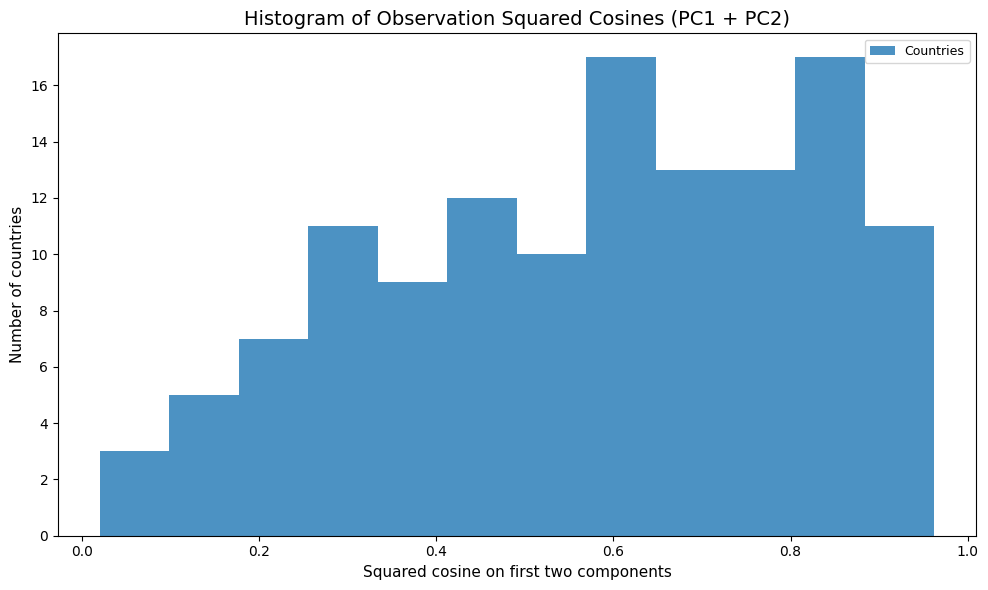

Interpretation: observations with larger PC1+PC2 squared cosine values are better represented by the two-dimensional PCA map; small values mean much of their profile lies outside the first two components.

47 of 128 countries (37%) have a PC1+PC2 squared cosine above 0.70, meaning the two-dimensional map captures most of their standardized profile. Their positions in the PCA scatter plot and biplot can be read with confidence.
24 countries (19%) fall below 0.30, meaning a meaningful share of their variation across the seven indicators lies outside the first two components (most likely along PC3-PC5). Their apparent position on the 2-D map should be read cautiously, since it is an incomplete summary of their full profile.


In [10]:
# Task 7: Histogram of observation squared cosines for PC1 + PC2.
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(
    obs_cos2["PC1+PC2"].dropna(),
    bins=12,
    alpha=0.8,
    label="Countries",
)
ax.set_title("Histogram of Observation Squared Cosines (PC1 + PC2)")
ax.set_xlabel("Squared cosine on first two components")
ax.set_ylabel("Number of countries")
ax.legend(loc="best", frameon=True)
fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "task7_observation_cos2_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

print(
    "Interpretation: observations with larger PC1+PC2 squared cosine values are better "
    "represented by the two-dimensional PCA map; small values mean much of their profile "
    "lies outside the first two components."
)

# Quantify the shape of the histogram instead of describing it only visually.
valid_cos2 = obs_cos2["PC1+PC2"].dropna()
total_n = len(valid_cos2)
well_represented = int((valid_cos2 > 0.7).sum())
poorly_represented = int((valid_cos2 < 0.3).sum())
print(
    f"\n{well_represented} of {total_n} countries ({well_represented / total_n * 100:.0f}%) "
    f"have a PC1+PC2 squared cosine above 0.70, meaning the two-dimensional map captures "
    f"most of their standardized profile. Their positions in the PCA scatter plot and "
    f"biplot can be read with confidence.\n"
    f"{poorly_represented} countries ({poorly_represented / total_n * 100:.0f}%) fall below "
    f"0.30, meaning a meaningful share of their variation across the seven indicators lies "
    f"outside the first two components (most likely along PC3-PC5). Their apparent position "
    f"on the 2-D map should be read cautiously, since it is an incomplete summary of their "
    f"full profile."
)

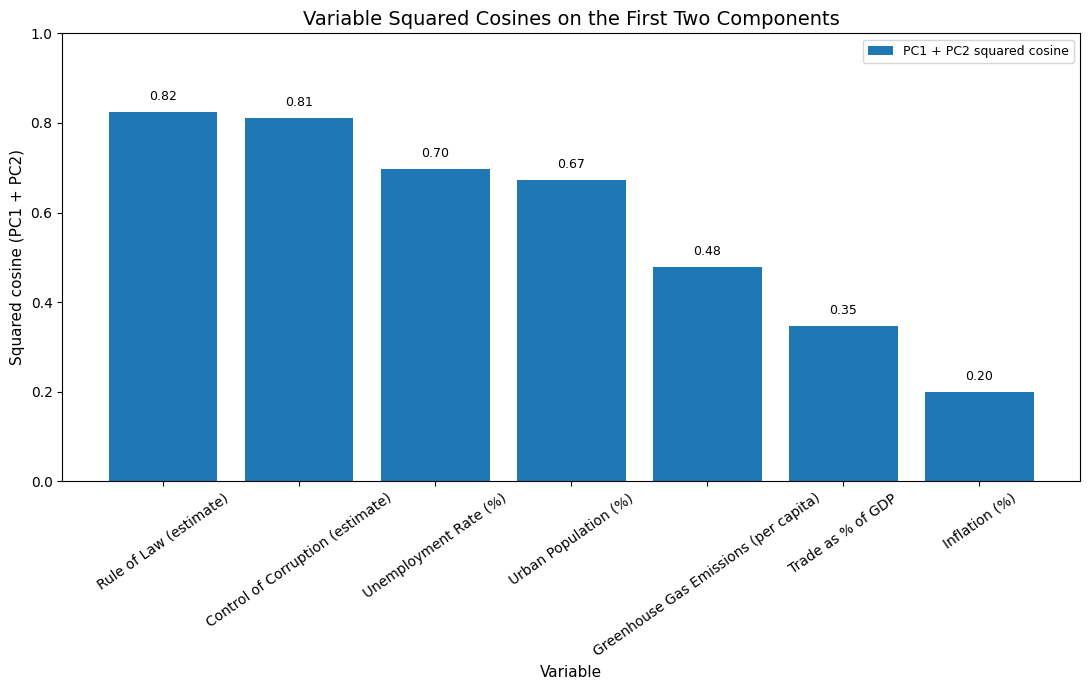

Key observation: Rule of Law (estimate) has the largest first-two-component squared cosine (0.823), so it is among the variables best captured in the PC1-PC2 map.
By contrast, Inflation (%) has the smallest first-two-component squared cosine (0.199). Its squared cosines across all five components sum to 0.999, so the 5-component model captures far more of its variation than the 2-D map does. Patterns involving Inflation (%) may be invisible in the 2-D scatterplot, correlation circle, or biplot, and are better read from the heatmap across all five components.


In [11]:
# Task 7: Vertical barplot of variable squared cosines for the first two components.
var_plot = var_cos2["PC1+PC2"].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.bar(
    [LABELS[v] for v in var_plot.index],
    var_plot.values,
    label="PC1 + PC2 squared cosine",
)

ax.set_title("Variable Squared Cosines on the First Two Components")
ax.set_xlabel("Variable")
ax.set_ylabel("Squared cosine (PC1 + PC2)")
ax.tick_params(axis="x", rotation=35)
ax.set_ylim(0, 1)
ax.legend(loc="best", frameon=True)

for bar, value in zip(bars, var_plot.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        min(value + 0.02, 0.98),
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

fig.tight_layout()
if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "task7_variable_cos2_barplot.png", dpi=300, bbox_inches="tight")
plt.show()

# Sum of squared cosines across all five components. This is computed rather than
# assumed, so the text stays correct if the data changes.
var_cos2_all_five = (var_corr ** 2).sum(axis=1)

best_var = var_plot.index[0]
worst_var = var_plot.index[-1]
print(
    f"Key observation: {LABELS[best_var]} has the largest first-two-component squared "
    f"cosine ({var_plot.iloc[0]:.3f}), so it is among the variables best captured in the "
    f"PC1-PC2 map."
)
print(
    f"By contrast, {LABELS[worst_var]} has the smallest first-two-component squared cosine "
    f"({var_plot.iloc[-1]:.3f}). Its squared cosines across all five components sum to "
    f"{var_cos2_all_five[worst_var]:.3f}, so the 5-component model captures far more of its "
    f"variation than the 2-D map does. Patterns involving {LABELS[worst_var]} may be "
    f"invisible in the 2-D scatterplot, correlation circle, or biplot, and are better read "
    f"from the heatmap across all five components."
)

### Squared cosines (Task 7)

For observations, the histogram shows a wide range. The median PC1+PC2 squared cosine is 0.60. Of the 128 countries, 47 (37%) exceed 0.70, so the two-dimensional map represents their profiles well, while 24 (19%) fall below 0.30, so their positions on the map are only a partial summary. A low value does not mean a poor fit for the data; it means most of that country's variation sits on the components beyond the first two.

For variables, the first two components represent Rule of Law (0.823) and Control of Corruption (0.810) best, followed by Unemployment rate (0.697) and Urban population (0.673). Greenhouse gas emissions (0.477) and trade (0.347) are only partly represented, and Inflation is the weakest at 0.199. Nearly all of inflation's variation lies on PC3 (its squared correlation with PC3 is about 0.77), and its squared cosines across all five components sum to 0.999. Inflation is therefore well represented by the five-component model but nearly invisible in the two-dimensional plots, which is why the heatmap below matters.

## Task 8 — PCA visualizations

The next cells create the five requested visuals:
1. PCA scatter plot of countries in PC1–PC2 space.
2. Correlation circle for variables on PC1 and PC2.
3. Heatmap of variable/component correlations across all five components.
4. Biplot combining countries and variable directions.
5. Data-driven interpretation of clusters, variable relationships, and overall PCA meaning.

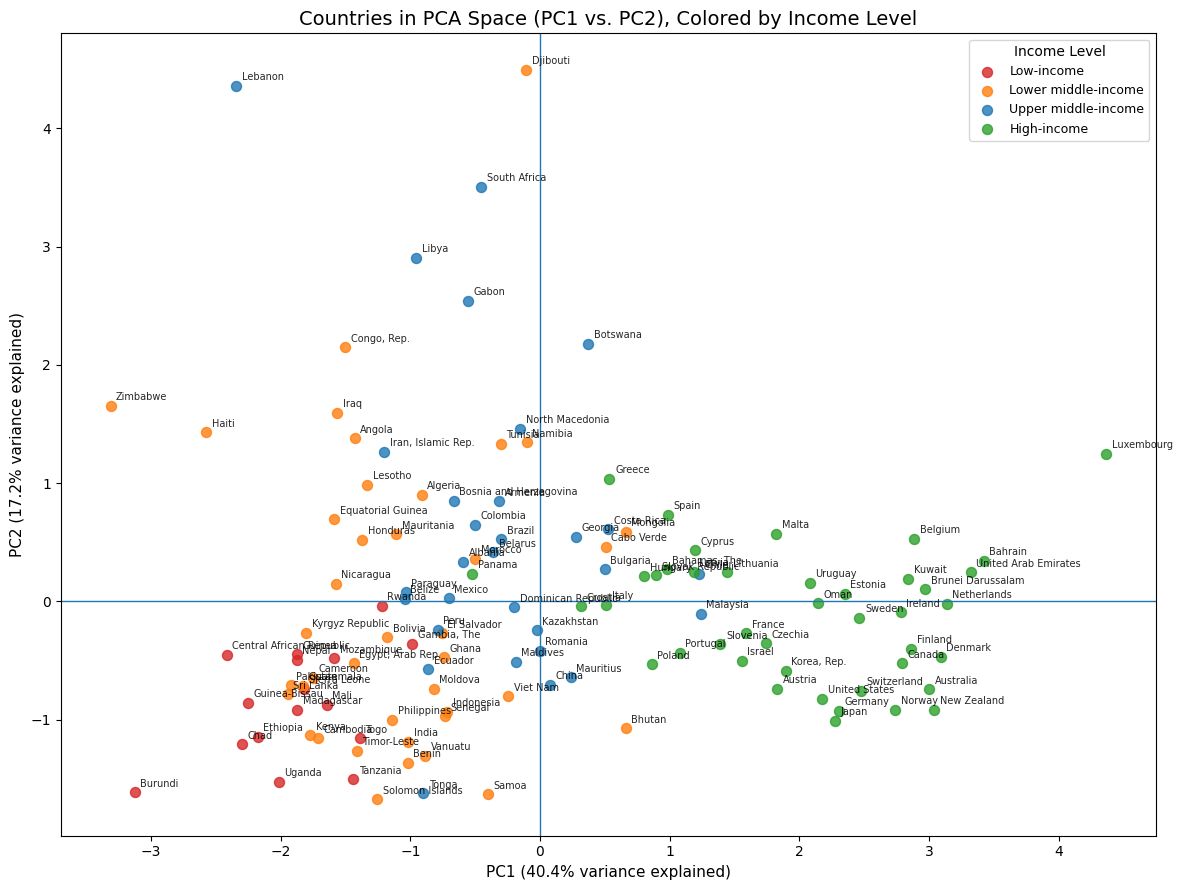

In [12]:
# Task 8a: PCA scatter plot of countries in the first two components,
# colored by Income_Level so income-based clustering (if any) is visible.
fig, ax = plt.subplots(figsize=(12, 9))

for level in INCOME_ORDER:
    subset = pca_scores[pca_scores["Income_Level"] == level]
    if subset.empty:
        continue
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        s=52,
        alpha=0.80,
        color=INCOME_COLORS[level],
        label=level,
    )

for country, row in pca_scores.iterrows():
    ax.annotate(
        country,
        (row["PC1"], row["PC2"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        alpha=0.85,
    )

ax.axhline(0, linewidth=1)
ax.axvline(0, linewidth=1)
ax.set_title("Countries in PCA Space (PC1 vs. PC2), Colored by Income Level")
ax.set_xlabel(f"PC1 ({explained_variance['PC1'] * 100:.1f}% variance explained)")
ax.set_ylabel(f"PC2 ({explained_variance['PC2'] * 100:.1f}% variance explained)")
ax.legend(title="Income Level", loc="best", frameon=True)
fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "task8_pca_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

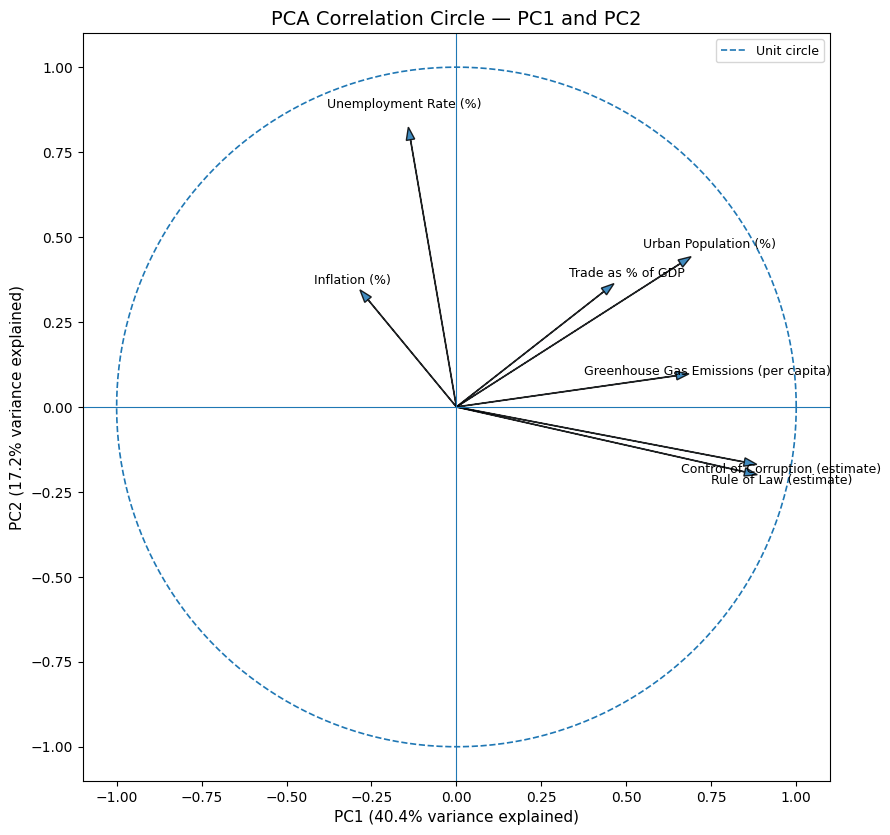

Correlation with PC1 and PC2:


,PC1,PC2
Inflation,-0.284,0.345
Trade_as_percent_GDP,0.464,0.363
Unemployment_rate,-0.142,0.823
GHG_Emissions_per_Capita,0.684,0.097
Urban_pop_percent,0.691,0.442
Control_of_Corruption,0.884,-0.169
Rule_of_Law,0.885,-0.199


In [13]:
# Task 8b: Correlation circle for variables in the first two components.
# Variable coordinates are their correlations with PC1 and PC2.
cor_circle = var_corr[["PC1", "PC2"]]

fig, ax = plt.subplots(figsize=(9, 9))

# Draw a unit circle to show the theoretical maximum correlation magnitude.
theta = np.linspace(0, 2 * np.pi, 400)
ax.plot(np.cos(theta), np.sin(theta), linestyle="--", linewidth=1.2, label="Unit circle")

# Draw variable arrows from the origin to their PC1/PC2 correlations.
for variable, row in cor_circle.iterrows():
    ax.arrow(
        0, 0,
        row["PC1"], row["PC2"],
        head_width=0.025,
        length_includes_head=True,
        alpha=0.85,
    )
    ax.text(
        row["PC1"] * 1.08,
        row["PC2"] * 1.08,
        LABELS[variable],
        fontsize=9,
        ha="center",
        va="center",
    )

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)
ax.set_title("PCA Correlation Circle — PC1 and PC2")
ax.set_xlabel(f"PC1 ({explained_variance['PC1'] * 100:.1f}% variance explained)")
ax.set_ylabel(f"PC2 ({explained_variance['PC2'] * 100:.1f}% variance explained)")
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_aspect("equal", adjustable="box")
ax.legend(loc="upper right", frameon=True)
fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "task8_correlation_circle.png", dpi=300, bbox_inches="tight")
plt.show()

print("Correlation with PC1 and PC2:")
display(cor_circle.round(3))

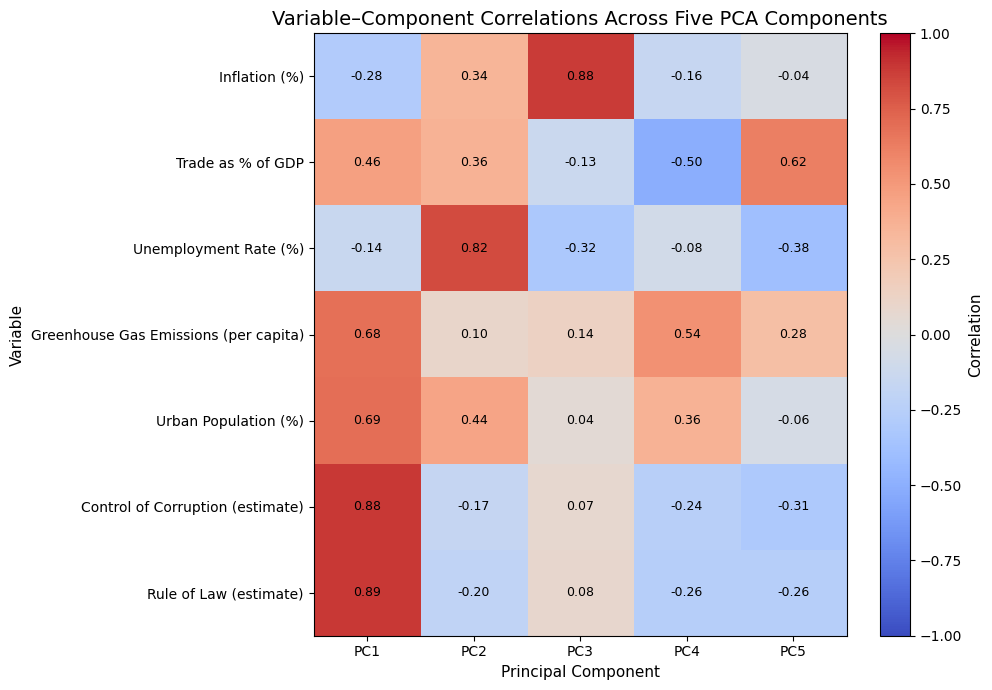

In [14]:
# ============================================================================
# TASK 8c: HEATMAP OF VARIABLE-COMPONENT CORRELATIONS
# ============================================================================

fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(
    var_corr.to_numpy(),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
)

ax.set_title("Variable–Component Correlations Across Five PCA Components")
ax.set_xlabel("Principal Component")
ax.set_ylabel("Variable")
ax.set_xticks(range(len(PC_NAMES)))
ax.set_xticklabels(PC_NAMES)
ax.set_yticks(range(len(var_corr.index)))
ax.set_yticklabels([LABELS[v] for v in var_corr.index])

# Print the actual correlation value in every cell for readability.
for i in range(var_corr.shape[0]):
    for j in range(var_corr.shape[1]):
        ax.text(j, i, f"{var_corr.iloc[i, j]:.2f}",
                ha="center", va="center", fontsize=9)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Correlation")
fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "task8_pca_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


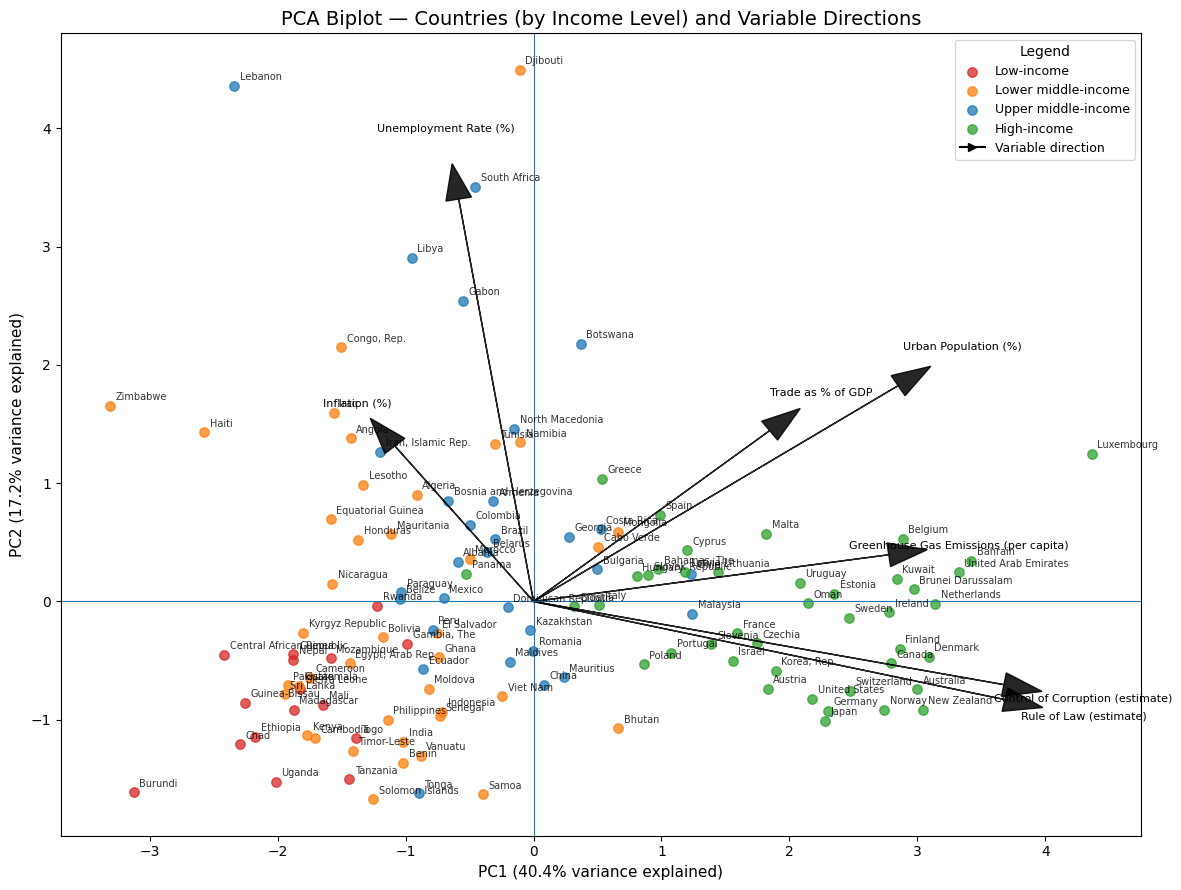

In [15]:
# Task 8d: Biplot combining country scores (colored by income level) and
# variable directions.
fig, ax = plt.subplots(figsize=(12, 9))

for level in INCOME_ORDER:
    subset = pca_scores[pca_scores["Income_Level"] == level]
    if subset.empty:
        continue
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        s=46,
        alpha=0.75,
        color=INCOME_COLORS[level],
        label=level,
    )

for country, row in pca_scores.iterrows():
    ax.annotate(
        country,
        (row["PC1"], row["PC2"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=7,
        alpha=0.80,
    )

# Scale variable arrows to make them visible on the country-score plot.
score_limit = max(
    np.abs(pca_scores[["PC1", "PC2"]].to_numpy()).max(),
    1.0,
)
arrow_scale = score_limit / 1.0

for variable, row in cor_circle.iterrows():
    ax.arrow(
        0, 0,
        row["PC1"] * arrow_scale,
        row["PC2"] * arrow_scale,
        head_width=0.045 * arrow_scale,
        length_includes_head=True,
        alpha=0.85,
        color="black",
    )
    ax.text(
        row["PC1"] * arrow_scale * 1.08,
        row["PC2"] * arrow_scale * 1.08,
        LABELS[variable],
        fontsize=8,
        ha="center",
        va="center",
    )

# Combine the automatic income-level legend with a manual entry for the
# variable-direction arrows.
from matplotlib.lines import Line2D
handles, legend_labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color="black", marker=">", linestyle="-", label="Variable direction"))
legend_labels.append("Variable direction")

ax.axhline(0, linewidth=0.8)
ax.axvline(0, linewidth=0.8)
ax.set_title("PCA Biplot — Countries (by Income Level) and Variable Directions")
ax.set_xlabel(f"PC1 ({explained_variance['PC1'] * 100:.1f}% variance explained)")
ax.set_ylabel(f"PC2 ({explained_variance['PC2'] * 100:.1f}% variance explained)")
ax.legend(handles=handles, labels=legend_labels, title="Legend", loc="best", frameon=True)
fig.tight_layout()

if SAVE_FIGURES:
    fig.savefig(OUTPUT_DIR / "task8_pca_biplot.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
# Task 8e: Generate data-driven PCA interpretation aids.

# Identify the variables with the strongest absolute correlations with each of PC1 and PC2.
pc1_strength = var_corr["PC1"].abs().sort_values(ascending=False)
pc2_strength = var_corr["PC2"].abs().sort_values(ascending=False)

# Identify pairs of variables that point in similar/opposite directions in the correlation circle.
variable_corr_matrix = analysis_df[PCA_VARS].corr()
pairs = []
for i, var_a in enumerate(PCA_VARS):
    for var_b in PCA_VARS[i + 1:]:
        pairs.append((var_a, var_b, variable_corr_matrix.loc[var_a, var_b]))
pairs = sorted(pairs, key=lambda t: abs(t[2]), reverse=True)

# Identify countries that are furthest from the origin in the PC1-PC2 map.
pca_scores["Distance_PC1_PC2"] = np.sqrt(
    pca_scores["PC1"]**2 + pca_scores["PC2"]**2
)
extreme_countries = pca_scores["Distance_PC1_PC2"].sort_values(ascending=False).head(5)

# Do the income-level colors in the scatter plot/biplot actually form a
# gradient along PC1, or is income-level clustering only partial?
pc1_by_income = pca_scores.groupby("Income_Level", observed=False)["PC1"].mean().reindex(INCOME_ORDER)
ordered_pc1 = pc1_by_income.dropna()
if len(ordered_pc1) >= 3 and ordered_pc1.is_monotonic_increasing:
    cluster_note = (
        "Average PC1 increases monotonically from Low-income to High-income, so the "
        "color-coded scatterplot/biplot above shows a genuine income gradient along the "
        "horizontal axis rather than income-level colors being scattered at random. This "
        "is consistent with PC1 being most strongly correlated with the governance "
        "variables (Control of Corruption, Rule of Law), which themselves tend to improve "
        "with income -- so PC1 is functioning as an implicit development/governance axis."
    )
elif len(ordered_pc1) >= 3 and ordered_pc1.is_monotonic_decreasing:
    cluster_note = (
        "Average PC1 decreases monotonically from Low-income to High-income, so the "
        "color-coded scatterplot/biplot above shows a genuine (reversed) income gradient "
        "along the horizontal axis rather than random scatter -- the sign of PC1 is "
        "arbitrary in PCA, so this is the same underlying pattern, just flipped."
    )
else:
    cluster_note = (
        "Average PC1 does not move in one consistent direction across the four income "
        "groups, so income-level clustering along PC1 is only partial -- some income "
        "groups overlap substantially in PCA space. That means the seven indicators used "
        "here capture dimensions of country variation (e.g. trade openness, unemployment) "
        "that are not fully explained by income group alone, even though PC1 leans heavily "
        "on the governance variables."
    )

print("PCA interpretation summary")
print("=" * 80)
print(
    f"1. The first two components explain {explained_variance.iloc[:2].sum() * 100:.1f}% "
    f"of the total standardized variance."
)
print(
    f"2. Strongest absolute PC1 relationship: {LABELS[pc1_strength.index[0]]} "
    f"(correlation = {var_corr.loc[pc1_strength.index[0], 'PC1']:.3f})."
)
print(
    f"3. Strongest absolute PC2 relationship: {LABELS[pc2_strength.index[0]]} "
    f"(correlation = {var_corr.loc[pc2_strength.index[0], 'PC2']:.3f})."
)

print("\n4. Clusters observed, by income level (see the colors in the scatter plot/biplot):")
print("   Average PC1 score by income level:")
for level, value in pc1_by_income.items():
    if pd.notna(value):
        print(f"   • {level}: mean PC1 = {value:.3f}")
    else:
        print(f"   • {level}: no observations")
print("   " + cluster_note)

print("\nStrongest variable relationships in the original seven-variable matrix:")
for var_a, var_b, corr in pairs[:5]:
    direction = "positive" if corr > 0 else "negative"
    print(f"• {LABELS[var_a]} vs. {LABELS[var_b]}: {direction} correlation of {corr:.3f}")

print("\nCountries farthest from the PC1-PC2 origin (potentially distinctive profiles):")
for country, distance in extreme_countries.items():
    print(f"• {country}: distance = {distance:.3f}")

PCA interpretation summary
1. The first two components explain 57.5% of the total standardized variance.
2. Strongest absolute PC1 relationship: Rule of Law (estimate) (correlation = 0.885).
3. Strongest absolute PC2 relationship: Unemployment Rate (%) (correlation = 0.823).

4. Clusters observed, by income level (see the colors in the scatter plot/biplot):
   Average PC1 score by income level:
   • Low-income: mean PC1 = -1.875
   • Lower middle-income: mean PC1 = -1.098
   • Upper middle-income: mean PC1 = -0.322
   • High-income: mean PC1 = 1.991
   Average PC1 increases monotonically from Low-income to High-income, so the color-coded scatterplot/biplot above shows a genuine income gradient along the horizontal axis rather than income-level colors being scattered at random. This is consistent with PC1 being most strongly correlated with the governance variables (Control of Corruption, Rule of Law), which themselves tend to improve with income -- so PC1 is functioning as an implicit 

### Task 8: explanation of the PCA visualizations

#### Clusters

The countries form a gradient along PC1 rather than sharply separated clusters, and income levels line up along it. The high-income countries form the most distinct group, on the right of the scatterplot. Mean PC1 scores rise from -1.87 for low-income countries, to -1.10 for lower-middle-income, -0.32 for upper-middle-income, and +1.99 for high-income. All 16 low-income countries have negative PC1 scores, and 41 of the 42 high-income countries have positive scores. The two middle groups overlap heavily with each other and with their neighbors: 22 of the 30 upper-middle-income countries still have negative PC1, and 3 of the 40 lower-middle-income countries have positive PC1.

The countries farthest from the origin are Lebanon, Luxembourg, Djibouti, Zimbabwe, and South Africa. Each is pulled out by one extreme value rather than by a general pattern. Lebanon's inflation of about 171% is about 8.8 standard deviations above the mean. Zimbabwe's inflation of about 105% is also extreme, about 5 standard deviations above the mean. Luxembourg's trade ratio of about 389% of GDP drives its position on the high-PC1 side, Djibouti combines trade of about 340% with unemployment of about 26%, and South Africa's unemployment of about 33% pushes it high on PC2, third-highest in the sample. Because PCA is built on variance (squared deviations from the mean), a single extreme value can dominate a country's position. A useful robustness check would be to log-transform inflation and trade and see whether these positions move.

#### Relationships between variables

The correlation circle and heatmap show three main patterns. Control of Corruption and Rule of Law point in almost the same direction, with a correlation of 0.94 between them, and both load strongly on PC1 (about 0.88). Greenhouse gas emissions and urban population also point together (correlation 0.54) and load positively on PC1 as well (0.68 and 0.69), so more urbanized, higher-emission countries also tend to have stronger governance. Unemployment is nearly unrelated to the governance axis (correlation with PC1 of about -0.14) and loads mainly on PC2 (about 0.82). Its correlations with the governance indicators are weakly negative (-0.14 and -0.18), so unemployment does not reflect the same development dimension as governance. Inflation points weakly against governance, with correlations of about -0.19 with both governance indicators.

#### Significance of the PCA model

The first two components give an interpretable summary. PC1 (40.4% of variance) is a governance and development axis: countries with strong institutions, high urbanization and emissions, high trade, and low inflation score high. PC2 (17.2%) is largely an unemployment axis, with inflation, trade, and urbanization pointing in the same direction and governance pointing the other way. The Kaiser criterion supports keeping these two components. The five-component model captures 93.8% of the variance, so it is a good approximation of the full data, but the two-dimensional plots leave part of the story out, especially for inflation and for countries that sit near the origin. The heatmap and squared-cosine values should be checked alongside the scatterplot and biplot before interpreting any single country's position.

## Final checklist and findings

This section confirms that the notebook covers each requested task:

- **Task 1:** `Income_Level`, four dummy variables, and the original GNI column removed from `analysis_df`.
- **Task 2:** Eight income-level boxplots (GNI plus the seven WDI indicators) in the required category order, with readable titles/axis labels and numerical summary statistics.
- **Task 6:** Control of Corruption vs. Rule of Law scatterplot, regression line, country labels, correlation, and $R^2$.
- **Task 7:** Five-component standardized PCA, variance-explained barplot, observation squared cosines, variable squared cosines, and comments.
- **Task 8:** PCA scatterplot, correlation circle, five-component correlation heatmap, biplot, and interpretation.

### Human-centered AI note

PCA can hide valuable information when results are displayed in only two dimensions. The variance-explained plot, squared-cosine measures, and five-component heatmap are included to make the dimensionality-reduction decisions transparent, interpretable, and auditable.